# PASCAL VOC 2012 Object Detection with YOLOv3-Tiny

This notebook trains a **YOLOv3-Tiny** object detector on the **PASCAL VOC 2012** dataset (20 object classes).

**Pipeline overview:**
1. Install dependencies and import libraries
2. Load the VOC 2012 dataset via TensorFlow Datasets
3. Preprocess images (letterbox resize to 416×416) and convert boxes to YOLO format
4. Build YOLO training targets for the 13×13 and 26×26 detection grids
5. Define the YOLOv3-Tiny network and the YOLO loss function
6. Train with a custom loop and save the best model weights
7. Plot the training/validation loss curves

# 1. Import Libraries & Dataset

In [1]:
# Install the required packages.
# - tfds-nightly : TensorFlow Datasets (provides the VOC 2012 dataset)
# - tensorflow   : deep learning framework used to build and train the model
# - matplotlib   : plotting (visualization of samples and loss curves)
!pip install -q tfds-nightly tensorflow matplotlib importlib_resources

In [2]:
import pandas as pd                      # tabular data handling (utility)
from PIL import Image                    # image loading/saving utilities
import os                                # filesystem operations (paths, folders)
import xml.etree.ElementTree as ET       # parsing Pascal VOC XML annotations (if needed)
import random                            # Python random number generator
import matplotlib.pyplot as plt          # plotting and visualization
import seaborn as sns                    # statistical visualization (utility)
import cv2                               # OpenCV: fast image resizing
import numpy as np                       # numerical arrays and math
import tensorflow as tf                  # deep learning framework
import tensorflow_datasets as tfds       # ready-to-use datasets (VOC 2012)
from sklearn.model_selection import train_test_split  # (utility) splitting helpers
import json                              # JSON read/write (utility)
import time                              # timing each training epoch

# Google Colab Drive access is only available inside Colab.
# Import it defensively so the notebook also runs outside Colab
# (e.g. locally or on Kaggle) without raising an ImportError.
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print("Not running in Google Colab - Drive mounting will be skipped.")

In [3]:
# Fix all random seeds so that results are reproducible across runs.
SEED = 42
np.random.seed(SEED)        # NumPy RNG (shuffling, sampling)
random.seed(SEED)           # Python built-in RNG
tf.random.set_seed(SEED)    # TensorFlow RNG (weight init, data pipeline)

In [4]:
# Load the PASCAL VOC 2012 dataset from TensorFlow Datasets.
# - with_info=True   : also return metadata (class names, splits, features)
# - shuffle_files=True: shuffle the TFRecord shards for better randomness
# Available splits: 'train' (5717), 'validation' (5823), 'test' (10991, unannotated)
voc_ds, info = tfds.load('voc/2012', with_info=True, shuffle_files=True)

# Display dataset metadata: features, splits, sizes, citation, etc.
print(info)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/voc/2012/incomplete.HBRPOI_5.0.0/voc-test.tfrecord-[0-9][0-9][0-9][0-9][0-…

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/voc/2012/incomplete.HBRPOI_5.0.0/voc-train.tfrecord-[0-9][0-9][0-9][0-9][0…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/voc/2012/incomplete.HBRPOI_5.0.0/voc-validation.tfrecord-[0-9][0-9][0-9][0…

Dataset voc downloaded and prepared to /root/tensorflow_datasets/voc/2012/5.0.0. Subsequent calls will reuse this data.
tfds.core.DatasetInfo(
    name='voc',
    full_name='voc/2012/5.0.0',
    description="""
    This dataset contains the data from the PASCAL Visual Object Classes Challenge,
    corresponding to the Classification and Detection competitions.
    
    In the Classification competition, the goal is to predict the set of labels
    contained in the image, while in the Detection competition the goal is to
    predict the bounding box and label of each individual object.
    annotations.
    """,
    config_description="""
    This dataset contains the data from the PASCAL Visual Object Classes Challenge
    2012, a.k.a. VOC2012.
    
    A total of 11540 images are included in this dataset, where each image
    contains a set of objects, out of 20 different classes, making a total of
    27450 annotated objects.
    
    """,
    homepage='http://host.robots.ox.ac.uk/pas

# 2. Data Splitting

In [5]:
# VOC 2012 already provides official train/validation splits, so we use
# them directly instead of splitting manually.
# The official 'test' split has NO annotations, so it cannot be used for
# training or evaluation - we validate on the 'validation' split instead.
train_dataset = voc_ds['train']
val_dataset = voc_ds['validation']

# Sanity check: print the number of examples in each split.
print("Training examples:", info.splits['train'].num_examples)
print("Validation examples:", info.splits['validation'].num_examples)

Training examples: 5717
Validation examples: 5823


In [6]:
# Choose where the trained model weights will be saved.
# In Google Colab we mount Google Drive so the weights persist after the
# session ends. Outside Colab we fall back to a local folder so that this
# cell never raises an error.
if IN_COLAB:
    drive.mount('/content/drive')
    SAVE_DIR = '/content/drive/MyDrive/voc_project'
else:
    SAVE_DIR = './voc_project'

# Create the directory if it does not exist yet.
os.makedirs(SAVE_DIR, exist_ok=True)
print("Model weights will be saved to:", SAVE_DIR)

Mounted at /content/drive
Model weights will be saved to: /content/drive/MyDrive/voc_project


# 3. YOLOv3-Tiny

In [7]:
# Environment check: confirm the TensorFlow version and whether a GPU
# is available (training on CPU would be extremely slow).
print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [8]:
# ----------------------------- Hyperparameters -----------------------------
IMG_SIZE = 416      # network input resolution (416 x 416 pixels)
NUM_CLASSES = 20    # VOC 2012 has 20 object classes
BATCH_SIZE = 16     # images per training step
EPOCHS = 50         # number of full passes over the training set

# YOLOv3-Tiny anchor boxes (width, height) in pixels for 416x416 input.
# Anchors are prior box shapes found by clustering the training boxes;
# the first 3 (small) anchors belong to the 26x26 head (small objects),
# the last 3 (large) anchors belong to the 13x13 head (large objects).
ANCHORS = np.array([
    [10, 14],
    [23, 27],
    [37, 58],
    [81, 82],
    [135, 169],
    [344, 319]
], dtype=np.float32)

# Downsampling factor of each detection scale relative to the input image:
# 416 / 32 = 13  (coarse grid, large objects)
# 416 / 16 = 26  (fine grid, small objects)
STRIDES = [32, 16]

print("Input size:", IMG_SIZE)
print("Number of classes:", NUM_CLASSES)
print("Detection scales:", IMG_SIZE // 32, "and", IMG_SIZE // 16)
print("Anchors:\n", ANCHORS)

Input size: 416
Number of classes: 20
Detection scales: 13 and 26
Anchors:
 [[ 10.  14.]
 [ 23.  27.]
 [ 37.  58.]
 [ 81.  82.]
 [135. 169.]
 [344. 319.]]


In [9]:
# Build mappings between class names and integer ids (0..19).
# The class names come from the dataset metadata, so they always match
# the label encoding used by TFDS.
class_names = info.features['objects']['label'].names

class_to_id = {name: i for i, name in enumerate(class_names)}  # name -> id
id_to_class = {i: name for i, name in enumerate(class_names)}  # id -> name

print("Number of classes:", len(class_names))
print(class_to_id)

Number of classes: 20
{'aeroplane': 0, 'bicycle': 1, 'bird': 2, 'boat': 3, 'bottle': 4, 'bus': 5, 'car': 6, 'cat': 7, 'chair': 8, 'cow': 9, 'diningtable': 10, 'dog': 11, 'horse': 12, 'motorbike': 13, 'person': 14, 'pottedplant': 15, 'sheep': 16, 'sofa': 17, 'train': 18, 'tvmonitor': 19}


In [10]:
def prepare_image_and_boxes(example):
    """
    Preprocess one TFDS example for YOLO training.

    Steps:
      1. Resize the image to fit 416x416 while preserving aspect ratio
         (letterbox) and pad the remaining area with gray (128).
      2. Transform every bounding box so it matches the resized/padded
         image, then convert it to YOLO format:
         [class_id, x_center, y_center, width, height] with all
         coordinates normalized to [0, 1] relative to 416x416.

    Returns:
      image : float32 array of shape (416, 416, 3), scaled to [0, 1]
      boxes : float32 array of shape (N, 5) in YOLO format
    """
    # Convert the TFDS tensors to NumPy arrays.
    image = example['image'].numpy()
    height, width = image.shape[:2]

    # ----- Letterbox resize: scale so the longest side equals IMG_SIZE -----
    scale = min(IMG_SIZE / width, IMG_SIZE / height)
    new_width = int(width * scale)
    new_height = int(height * scale)
    resized = cv2.resize(image, (new_width, new_height))

    # ----- Pad the resized image onto a gray 416x416 canvas (centered) -----
    canvas = np.full((IMG_SIZE, IMG_SIZE, 3), 128, dtype=np.uint8)
    pad_x = (IMG_SIZE - new_width) // 2   # horizontal padding on each side
    pad_y = (IMG_SIZE - new_height) // 2  # vertical padding on each side
    canvas[pad_y:pad_y + new_height, pad_x:pad_x + new_width] = resized

    # TFDS boxes are normalized [ymin, xmin, ymax, xmax].
    original_boxes = example['objects']['bbox'].numpy()
    labels = example['objects']['label'].numpy()

    yolo_boxes = []
    for bbox, label in zip(original_boxes, labels):
        ymin, xmin, ymax, xmax = bbox

        # Convert normalized coords to pixel coords in the original image.
        xmin *= width
        xmax *= width
        ymin *= height
        ymax *= height

        # Apply the same resize + padding transform to the box.
        xmin = xmin * scale + pad_x
        xmax = xmax * scale + pad_x
        ymin = ymin * scale + pad_y
        ymax = ymax * scale + pad_y

        # Convert to YOLO format: normalized center x/y + width/height.
        x_center = (xmin + xmax) / 2 / IMG_SIZE
        y_center = (ymin + ymax) / 2 / IMG_SIZE
        box_width = (xmax - xmin) / IMG_SIZE
        box_height = (ymax - ymin) / IMG_SIZE

        yolo_boxes.append([
            int(label), x_center, y_center, box_width, box_height
        ])

    # Normalize pixel values to [0, 1]; reshape handles images with 0 boxes.
    return canvas.astype(np.float32) / 255.0, np.array(
        yolo_boxes, dtype=np.float32
    ).reshape(-1, 5)

In [11]:
# Spatial resolution of the two detection grids for a 416x416 input:
#   416 / 32 = 13  -> index 0 -> large objects (large anchors)
#   416 / 16 = 26  -> index 1 -> small objects (small anchors)
GRID_SIZES = [13, 26]

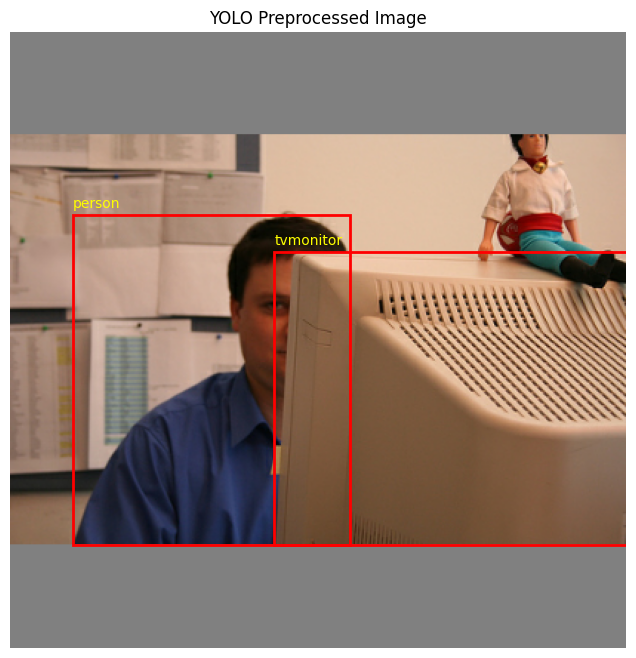

In [12]:
# Take one training example and run it through the preprocessing pipeline
# to visually verify that the boxes still align with the objects after
# resizing and padding.
sample = next(iter(voc_ds['train'].take(1)))
processed_image, processed_boxes = prepare_image_and_boxes(sample)

plt.figure(figsize=(8, 8))
plt.imshow(processed_image)

# Draw every ground-truth box together with its class name.
for box in processed_boxes:
    class_id, xc, yc, bw, bh = box

    # Convert YOLO (normalized center + size) back to pixel corners.
    x1 = int((xc - bw / 2) * IMG_SIZE)
    y1 = int((yc - bh / 2) * IMG_SIZE)
    x2 = int((xc + bw / 2) * IMG_SIZE)
    y2 = int((yc + bh / 2) * IMG_SIZE)

    plt.gca().add_patch(
        plt.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False, edgecolor='red', linewidth=2
        )
    )
    plt.text(
        x1, max(y1 - 5, 0),
        id_to_class[int(class_id)],
        color='yellow', fontsize=10
    )

plt.title("YOLO Preprocessed Image")
plt.axis('off')
plt.show()

In [13]:
def create_targets(boxes):
    """
    Convert a list of YOLO-format boxes into the two training target
    tensors (one per detection scale).

    Each target has shape (grid, grid, 3 anchors, 5 + NUM_CLASSES) where
    the last dimension stores:
      [objectness, x_offset, y_offset, w_log, h_log, one-hot class...]

    For each ground-truth box:
      1. Find the anchor with the highest IoU against the box.
      2. Route the box to the correct scale:
         small anchors (0-2) -> 26x26 grid, large anchors (3-5) -> 13x13 grid.
      3. Compute which grid cell is responsible for the box center.
      4. Encode the box center as an offset inside that cell and the
         size as a log-ratio relative to the anchor.
    """
    # Start with all-zero targets (no object anywhere).
    targets = [
        np.zeros((13, 13, 3, 5 + NUM_CLASSES), dtype=np.float32),
        np.zeros((26, 26, 3, 5 + NUM_CLASSES), dtype=np.float32)
    ]

    for box in boxes:
        class_id, xc, yc, bw, bh = box

        # Box size in pixels, to compare with the pixel-sized anchors.
        box_wh = np.array([bw, bh]) * IMG_SIZE

        # IoU between the box and every anchor, aligned at the origin
        # (anchor matching ignores position - only shape matters).
        intersection = np.minimum(box_wh, ANCHORS).prod(axis=1)
        union = box_wh.prod() + ANCHORS.prod(axis=1) - intersection
        iou = intersection / (union + 1e-9)  # epsilon avoids division by 0

        best_anchor = np.argmax(iou)

        # Anchors 0-2 (small) belong to the 26x26 head (scale index 1),
        # anchors 3-5 (large) belong to the 13x13 head (scale index 0).
        if best_anchor < 3:
            scale_index = 1
            anchor_index = best_anchor
        else:
            scale_index = 0
            anchor_index = best_anchor - 3

        grid_size = GRID_SIZES[scale_index]

        # Grid cell that contains the box center (clamped to valid range).
        grid_x = min(int(xc * grid_size), grid_size - 1)
        grid_y = min(int(yc * grid_size), grid_size - 1)

        # Center position as a fractional offset inside the cell (0..1).
        x_offset = xc * grid_size - grid_x
        y_offset = yc * grid_size - grid_y

        # Box size as log-ratio relative to the matched anchor
        # (the network will learn to predict these log values).
        anchor = ANCHORS[best_anchor]
        w_offset = np.log(bw * IMG_SIZE / anchor[0] + 1e-9)
        h_offset = np.log(bh * IMG_SIZE / anchor[1] + 1e-9)

        # Write the ground truth: objectness=1, offsets, log-size, one-hot class.
        targets[scale_index][grid_y, grid_x, anchor_index] = [
            1.0, x_offset, y_offset, w_offset, h_offset
        ] + [
            1.0 if i == int(class_id) else 0.0
            for i in range(NUM_CLASSES)
        ]

    return targets[0], targets[1]

In [14]:
# Maximum number of boxes kept per image (reserved for padding strategies;
# not needed here because targets are dense grid tensors).
MAX_BOXES = 100

def dataset_generator(split):
    """
    Python generator that yields one (image, targets) pair at a time.
    Iterating over voc_ds[split] restarts from the beginning each epoch.
    """
    for example in voc_ds[split]:
        image, boxes = prepare_image_and_boxes(example)      # preprocess
        target_13, target_26 = create_targets(boxes)         # build targets
        yield image, (target_13, target_26)

# Declare the exact shape/dtype the generator yields so tf.data can build
# static graph tensors: image (416,416,3) + two target grids.
OUTPUT_SIGNATURE = (
    tf.TensorSpec(shape=(416, 416, 3), dtype=tf.float32),
    (
        tf.TensorSpec(shape=(13, 13, 3, 25), dtype=tf.float32),
        tf.TensorSpec(shape=(26, 26, 3, 25), dtype=tf.float32)
    )
)

# Wrap the Python generators in tf.data.Dataset objects.
train_data = tf.data.Dataset.from_generator(
    lambda: dataset_generator('train'),
    output_signature=OUTPUT_SIGNATURE
)
val_data = tf.data.Dataset.from_generator(
    lambda: dataset_generator('validation'),
    output_signature=OUTPUT_SIGNATURE
)

# Training pipeline: shuffle -> batch -> prefetch (overlaps data prep with GPU work).
train_data = (
    train_data
    .shuffle(1000)                      # buffer of 1000 samples for shuffling
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Validation pipeline: no shuffling needed.
val_data = (
    val_data
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Training and validation datasets are ready.")

Training and validation datasets are ready.


# 4. Model Architecture

In [15]:
def conv_block(x, filters, kernel_size, strides=1):
    """
    Standard YOLO building block: Conv2D -> BatchNorm -> LeakyReLU.
    use_bias=False because the following BatchNorm already learns a bias.
    padding='same' keeps the spatial size unchanged (unless strides > 1).
    """
    x = tf.keras.layers.Conv2D(
        filters, kernel_size,
        strides=strides, padding='same',
        use_bias=False
    )(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.LeakyReLU(alpha=0.1)(x)
    return x

In [16]:
def build_yolov3_tiny():
    """
    Build the YOLOv3-Tiny network (2 detection scales).

    Feature map sizes for a 416x416 input:
      after pool 1-4 : 208 -> 104 -> 52 -> 26  ('route' = 26x26x256)
      after pool 5   : 13x13 (stride-32 features for large objects)

    Head 1 (13x13): detects LARGE objects with the 3 large anchors.
    Head 2 (26x26): upsamples the deep 13x13 features and merges them
    with the 26x26 'route' features (skip connection) to detect
    SMALL objects with the 3 small anchors.

    Each head outputs 3 anchors x (4 box coords + 1 objectness + 20 classes)
    = 75 channels.
    """
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    # ------------------------- Backbone -------------------------
    x = conv_block(inputs, 16, 3)                       # 416 x 416 x 16
    x = tf.keras.layers.MaxPooling2D(2, 2, padding='same')(x)   # 208
    x = conv_block(x, 32, 3)                            # 208 x 208 x 32
    x = tf.keras.layers.MaxPooling2D(2, 2, padding='same')(x)   # 104
    x = conv_block(x, 64, 3)                            # 104 x 104 x 64
    x = tf.keras.layers.MaxPooling2D(2, 2, padding='same')(x)   # 52
    x = conv_block(x, 128, 3)                           # 52 x 52 x 128
    x = tf.keras.layers.MaxPooling2D(2, 2, padding='same')(x)   # 26
    x = conv_block(x, 256, 3)                           # 26 x 26 x 256

    # Keep the 26x26 features for the skip connection of head 2.
    route = x

    x = tf.keras.layers.MaxPooling2D(2, 2, padding='same')(x)   # 13
    x = conv_block(x, 512, 3)                           # 13 x 13 x 512
    # Stride-1 pooling: downsamples only if needed, keeps 13x13 here.
    x = tf.keras.layers.MaxPooling2D(2, 1, padding='same')(x)
    x = conv_block(x, 1024, 3)                          # 13 x 13 x 1024

    # ------------- Detection head 1: 13x13 (large objects) -------------
    x = conv_block(x, 256, 1)                           # 13 x 13 x 256
    x = conv_block(x, 512, 3)                           # 13 x 13 x 512
    output_13 = tf.keras.layers.Conv2D(
        3 * (5 + NUM_CLASSES), 1, padding='same',
        name='detection_13'
    )(x)                                                # 13 x 13 x 75

    # ------------- Detection head 2: 26x26 (small objects) -------------
    # Branch off the deep 13x13 features, compress them, then upsample
    # x2 so the spatial size matches the 26x26 'route' features.
    x = conv_block(x, 128, 1)                           # 13 x 13 x 128
    x = tf.keras.layers.UpSampling2D(2)(x)              # 26 x 26 x 128
    # Skip connection: fuse fine-grained (route) + semantic (upsampled) features.
    x = tf.keras.layers.Concatenate()([x, route])       # 26 x 26 x 384
    x = conv_block(x, 256, 3)                           # 26 x 26 x 256
    output_26 = tf.keras.layers.Conv2D(
        3 * (5 + NUM_CLASSES), 1, padding='same',
        name='detection_26'
    )(x)                                                # 26 x 26 x 75

    model = tf.keras.Model(
        inputs=inputs,
        outputs=[output_13, output_26],
        name='YOLOv3_Tiny'
    )
    return model

In [17]:
# Instantiate the model and print its architecture plus the two output
# shapes as a sanity check: (None, 13, 13, 75) and (None, 26, 26, 75).
model = build_yolov3_tiny()
model.summary()

print("\nModel output shapes:")
for output in model.outputs:
    print(output.shape)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


Model: "YOLOv3_Tiny"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 416, 416,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 416, 416,  │        432 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 416, 416,  │         64 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 416, 416,  │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 208, 208,  │          0 │ leaky_re_lu[0][0] │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 208, 208,  │      4,608 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 208, 208,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 208, 208,  │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 104, 104,  │          0 │ leaky_re_lu_1[0]… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 104, 104,  │     18,432 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 104, 104,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_2       │ (None, 104, 104,  │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 52, 52,    │          0 │ leaky_re_lu_2[0]… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 52, 52,    │     73,728 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 52, 52,    │        512 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_3       │ (None, 52, 52,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 26, 26,    │          0 │ leaky_re_lu_3[0]

 Total params: 8,752,902 (33.39 MB)

 Trainable params: 8,746,534 (33.37 MB)

 Non-trainable params: 6,368 (24.88 KB)


Model output shapes:
(None, 13, 13, 75)
(None, 26, 26, 75)


# 5. Loss Function

In [18]:
def yolo_loss(y_true, y_pred):
    """
    YOLO loss for ONE detection scale.

    y_true layout (built by create_targets):
        [obj, x_off, y_off, w_log, h_log, one-hot class...]   -> obj at index 0
    y_pred layout (raw network output, reshaped to (..., 3, 25)):
        [tx, ty, tw, th, obj_logit, class_logits...]          -> obj at index 4

    Total loss = weighted sum of:
      - center (x, y) MSE        (only where an object exists)
      - size   (w, h) MSE        (only where an object exists)
      - objectness BCE           (everywhere; non-object cells weighted 0.5)
      - class BCE                (only where an object exists)
    """
    batch_size = tf.shape(y_pred)[0]
    grid_h = tf.shape(y_pred)[1]
    grid_w = tf.shape(y_pred)[2]

    # Reshape the flat 75 channels into (3 anchors, 5 + NUM_CLASSES values).
    y_pred = tf.reshape(
        y_pred,
        (batch_size, grid_h, grid_w, 3, 5 + NUM_CLASSES)
    )

    # ----- Ground truth components -----
    obj_mask = y_true[..., 0:1]    # 1 where a box is assigned, else 0
    true_xy = y_true[..., 1:3]     # center offset inside the cell
    true_wh = y_true[..., 3:5]     # log-size relative to the anchor
    true_class = y_true[..., 5:]   # one-hot class vector

    # ----- Prediction components -----
    pred_xy = tf.sigmoid(y_pred[..., 0:2])  # squash center into (0, 1)
    pred_wh = y_pred[..., 2:4]              # log-size (linear output)
    pred_obj = y_pred[..., 4:5]             # objectness logit
    pred_class = y_pred[..., 5:]            # class logits

    # ----- Box center loss (objects only) -----
    # 1e-6 avoids division by zero for images without any object.
    xy_loss = tf.reduce_sum(
        obj_mask * tf.square(true_xy - pred_xy)
    ) / (tf.reduce_sum(obj_mask) + 1e-6)

    # ----- Box size loss (objects only) -----
    wh_loss = tf.reduce_sum(
        obj_mask * tf.square(true_wh - pred_wh)
    ) / (tf.reduce_sum(obj_mask) + 1e-6)

    # ----- Objectness loss (all cells) -----
    obj_bce = tf.nn.sigmoid_cross_entropy_with_logits(
        labels=obj_mask, logits=pred_obj
    )
    # Down-weight background cells (0.5) so they don't dominate the loss.
    obj_weights = obj_mask + 0.5 * (1 - obj_mask)
    obj_loss = tf.reduce_mean(obj_bce * obj_weights)

    # ----- Classification loss (objects only) -----
    class_bce = tf.nn.sigmoid_cross_entropy_with_logits(
        labels=true_class, logits=pred_class
    )
    class_loss = tf.reduce_sum(
        class_bce * obj_mask
    ) / (tf.reduce_sum(obj_mask) + 1e-6)

    # Coordinate losses get a higher weight (5.0), as in the YOLO paper.
    total_loss = (
        5.0 * xy_loss +
        5.0 * wh_loss +
        obj_loss +
        class_loss
    )
    return total_loss

In [19]:
def calculate_total_loss(targets, predictions):
    """
    Sum the YOLO loss over both detection scales (13x13 and 26x26).
    targets     : tuple (target_13, target_26) from the data pipeline
    predictions : list  [output_13, output_26] from the model
    """
    target_13, target_26 = targets
    pred_13, pred_26 = predictions

    loss_13 = yolo_loss(target_13, pred_13)
    loss_26 = yolo_loss(target_26, pred_26)

    return loss_13 + loss_26

# 6. Training

In [20]:
# Adam optimizer with a small learning rate - YOLO training is sensitive
# and a large learning rate can easily make the loss diverge.
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001)

# Tracks the best (lowest) validation loss seen so far; the model is saved
# to disk only when this improves.
best_val_loss = float('inf')

In [21]:
# @tf.function compiles each step into a TensorFlow graph for speed.

@tf.function
def train_step(images, targets):
    """One training step: forward pass, compute loss, apply gradients."""
    with tf.GradientTape() as tape:
        # training=True -> BatchNorm uses batch statistics and updates
        # its moving averages.
        predictions = model(images, training=True)
        loss = calculate_total_loss(targets, predictions)

    # Backpropagate and update the weights.
    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, model.trainable_variables))
    return loss


@tf.function
def validation_step(images, targets):
    """One validation step: forward pass only, no weight updates."""
    # training=False -> BatchNorm uses its stored moving averages.
    predictions = model(images, training=False)
    loss = calculate_total_loss(targets, predictions)
    return loss

In [22]:
EPOCHS = 50

# Store per-epoch losses so they can be plotted afterwards.
history = {'train_loss': [], 'val_loss': []}

for epoch in range(EPOCHS):
    start_time = time.time()
    train_losses, val_losses = [], []

    # ---------------- Training pass over the whole train set ----------------
    for images, targets in train_data:
        loss = train_step(images, targets)
        train_losses.append(float(loss))

    # ---------------- Validation pass (no gradient updates) ----------------
    for images, targets in val_data:
        loss = validation_step(images, targets)
        val_losses.append(float(loss))

    # Average the batch losses to get one number per epoch.
    train_loss = np.mean(train_losses)
    val_loss = np.mean(val_losses)
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)

    # Checkpoint: save weights whenever the validation loss improves.
    # The '.weights.h5' suffix is required by Keras 3 for save_weights.
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        model.save_weights(f"{SAVE_DIR}/yolov3_tiny_best.weights.h5")

    elapsed = time.time() - start_time
    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Time: {elapsed:.1f}s"
    )

Epoch 1/50 | Train Loss: 19.7082 | Val Loss: 24.5060 | Time: 180.3s
Epoch 2/50 | Train Loss: 10.8763 | Val Loss: 10.9413 | Time: 128.1s
Epoch 3/50 | Train Loss: 9.7418 | Val Loss: 10.6593 | Time: 147.9s
Epoch 4/50 | Train Loss: 8.9894 | Val Loss: 10.2710 | Time: 162.7s
Epoch 5/50 | Train Loss: 8.5907 | Val Loss: 10.0568 | Time: 161.2s
Epoch 6/50 | Train Loss: 8.1093 | Val Loss: 9.8714 | Time: 126.1s
Epoch 7/50 | Train Loss: 7.5563 | Val Loss: 9.8539 | Time: 163.8s
Epoch 8/50 | Train Loss: 7.2568 | Val Loss: 9.8152 | Time: 130.8s
Epoch 9/50 | Train Loss: 6.7718 | Val Loss: 10.9387 | Time: 175.9s
Epoch 10/50 | Train Loss: 6.5250 | Val Loss: 9.7368 | Time: 118.8s
Epoch 11/50 | Train Loss: 6.1621 | Val Loss: 9.9038 | Time: 120.9s
Epoch 12/50 | Train Loss: 5.5954 | Val Loss: 10.3414 | Time: 120.1s
Epoch 13/50 | Train Loss: 5.1874 | Val Loss: 10.3645 | Time: 131.3s
Epoch 14/50 | Train Loss: 4.7973 | Val Loss: 9.9940 | Time: 123.5s
Epoch 15/50 | Train Loss: 4.3254 | Val Loss: 10.0355 | Time: 

# 7. Results

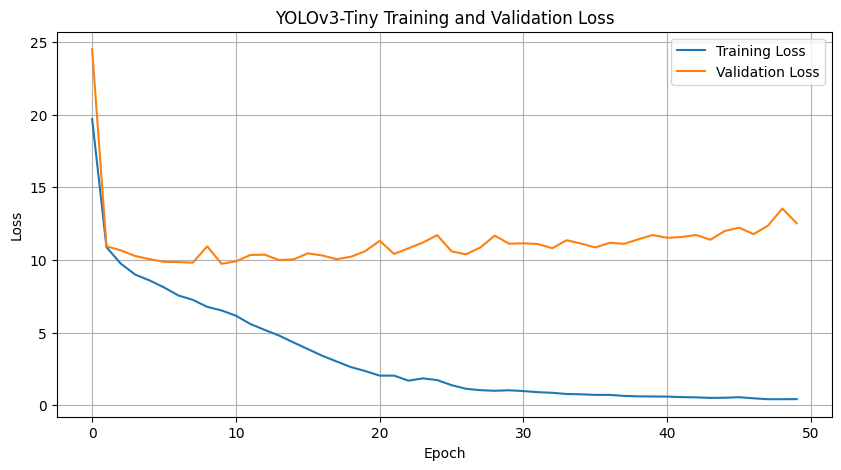

In [23]:
# Plot the training and validation loss curves to check convergence and
# spot overfitting (val loss rising while train loss keeps falling).
plt.figure(figsize=(10, 5))
plt.plot(history['train_loss'], label='Training Loss')
plt.plot(history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('YOLOv3-Tiny Training and Validation Loss')
plt.legend()
plt.grid()
plt.show()